# Template for coursework - Part 1 Classification

In [1]:
# Import of libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Nastavení stylu a rozměrů grafů
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
sns.set_theme(style="whitegrid")


## Team identification

Cvičení: Středa 18.00-19.30 SB M15
Skupina: Team 6 - What Makes an Instagram Reel Go Viral?
Členové: Kajetan Franciszek Wielgosz, Tomáš Duchoň, Adam Veselý, Adam Súkala, Natalie Stašková

# Introduction

0. Description of the chosen dataset

Náš tým si pro seminární práci vybral dataset pojmenovaný "What Makes an Instagram Reel Go Viral?". Tento dataset se skládá ze sta tisíc syntetických observací reprezentujících výkon Instagramových Reelů. Jedním z důvodů proč jsme dataset vybrali jsou právě syntetická data, kterých vliv na rozhodovací stromy a náhodný les chceme zachytit.

1.	Describe the business value of addressing this problem with machine learning. 

Kdybychom odhlédli od toho, že jde o syntetická data, tak dataset má z pohledu digitálního marketingu, sociálních sítí a tvůrců obsahu velmi vysokou byznysovou hodnotu. Zachycuje totiž celý životní cyklus Instagram Reelsů, specificky jejich produkčních parametry. Z byznysového hlediska bychom mohli řešit efektivní alokaci rozpočtu na placenou propagaci. Firmy a agentury často tlačí peníze do obsahu, který nemá moc velký potenciál na to se stát takzvaným virálem. Aby vyřešit tento problém špatně vynaložených prostředků, mohli bychom právě pomocí těchto dat predikovat jaký obsah má největší pravděpodobnost se stát "virálem". 

2.	Provide the link to the source of the data. 

https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral/data

## Customization

1.	What is the *target attribute*

Cílovým atributem pro klasifikační úlohu je nově odvozený binární atribut is_viral, který vznikl transformací původního spojitého atributu virality_score (nabývajícího hodnot v intervalu $\langle 0; 100 \rangle$).
Pozitivní třída (1): Příspěvek je považován za virální, pokud jeho virality_score >= 75 (tvoří přibližně horních 25 % nejúspěšnějších příspěvků v datasetu).
Negativní třída (0): Běžný (nevirální) příspěvek s hodnotou virality_score < 75 (zbývajících cca 75 % dat).

Původní sloupec virality_score je po této binarizaci z datové sady odstraněn (dale v předzpracování dat), aby nedošlo k úniku cílové informace.

2.	What is the *instance of interest*   The instance can be identified, for example, by an id.

Pro detailní analýzu a interpretaci chování modelů v závěrečné části práce byla z testovací množiny vybrána konkrétní instance (první řádek testovací sady po rozdělení v poměru 80:20 s parametrem random_state=42):

Index řádku v původním datasetu: 63769
Identifikátor příspěvku (reel_id): 90464090-f30f-4351-a667-e92d07f6b2bb
Charakteristika instance: Příspěvek tvůrce s 2 891 898 sledujícími, publikovaný v 15 hodin, o délce 52 sekund, s 8 hashtagy a využitým trendujícím zvukem (trending_audio = True). Jeho skutečné skóre virality činí 7,29, spadá tedy do negativní třídy (is_viral = 0).

3.	Choose an *attribute of interest* 

Jako atribut zájmu byl zvolen binární atribut trending_audio (nabývající hodnot True/1 při použití trendujícího zvuku a False/0 při použití vlastního či netrendujícího zvuku).


5.	Show *Cost matrix* consisting of a cost of a false positive, false negative, true positive and true negative. Note that cost of true positive and true negative is recommended to be zero.

V kontextu digitálního marketingu a optimalizace rozpočtu na placenou podporu příspěvků (Paid Boost) definujeme matici nákladů následovně:

* **Správná rozhodnutí:** $Cost(TP) = 0\text{ Kč}$, $Cost(TN) = 0\text{ Kč}$ (žádný dodatečný náklad ani ztráta).
* **Falešně pozitivní predikce (False Positive - FP):** Model predikuje, že příspěvek bude virální ($1$), ale ve skutečnosti virální není ($0$).
  * *Dopad:* Zbytečně vynaložený finanční náklad na placenou kampaň (boost) příspěvku, který nepřinese očekávaný virální organický dosah.
  * *Přiřazený náklad:* **100 Kč** (průměrná částka na otestování placené podpory jednoho videa).
* **Falešně negativní predikce (False Negative - FN):** Model predikuje, že příspěvek nebude virální ($0$), ale video mělo virální potenciál ($1$).
  * *Dopad:* Ušlá příležitost (opportunity cost) – promarněný virální organický dosah, nezískaní sledující, neuzavřené sponzorské spolupráce a nevyužitý dosah pro značku. V marketingu na sociálních sítích je přehlédnutí virálního hitu považováno za výrazně dražší chybu než menší neúspěšná kampaň.
  * *Přiřazený náklad:* **300 Kč** (odpovídá $3\times$ vyšší ztrátě oproti nákladu na FP).

| Skutečnost \ Predikce modelu | Predikce 0 (Nevirální) | Predikce 1 (Virální) |
| :--- | :---: | :---: |
| **Skutečnost 0 (Nevirální)** | $Cost(TN) = 0\text{ Kč}$ | $Cost(FP) = 100\text{ Kč}$ |
| **Skutečnost 1 (Virální)** | $Cost(FN) = 300\text{ Kč}$ | $Cost(TP) = 0\text{ Kč}$ |


# Data Exploration

### 1. Význam jednotlivých atributů (Describe meaning of individual attributes)
Dataset obsahuje 100 000 instancí a 26 atributů, které lze rozdělit do následujících logických skupin:

| Skupina | Atribut | Datový typ | Význam atributu |
| :--- | :--- | :---: | :--- |
| **Identifikátory** | `reel_id` | `object (UUID)` | Unikátní identifikátor příspěvku (videozáznamu). |
| | `creator_id` | `object (UUID)` | Unikátní identifikátor autora/tvůrce. |
| **Profil tvůrce** | `creator_followers` | `int64` | Celkový počet sledujících daného tvůrce (1 až 5 mil.). |
| **Metadata příspěvku** | `posting_time` | `int64` | Hodina zveřejnění příspěvku (0–23 hod.). |
| | `reel_length_sec` | `int64` | Celková délka videa v sekundách (5–60 s). |
| | `caption_length` | `int64` | Délka textového popisku videa v počtu znaků (0–300). |
| | `hashtags_count` | `int64` | Počet hashtagů použitých u příspěvku (0–30). |
| **Kvalitativní atributy** | `hook_strength_score` | `float64` | Kvalita / údernost prvních 3 sekund videa (interval 0.0–1.0). |
| | `trending_audio` | `bool` | Zda video využívá aktuálně trendující zvukovou stopu (True/False) – **atribut zájmu**. |
| | `audio_popularity_score` | `float64` | Míra popularity a používání použitého audia (0.0–1.0). |
| | `video_quality_score` | `float64` | Technická kvalita obrazu / rozlišení (0.0–1.0). |
| | `editing_quality_score` | `float64` | Úroveň střihu, efektů a dynamiky videa (0.0–1.0). |
| **Chování diváků** | `avg_watch_time_sec` | `float64` | Průměrná doba sledování videa uživateli v sekundách. |
| | `retention_rate` | `float64` | Míra udržení diváků (poměr shlédnuté části videa, 0.0–1.0). |
| | `completion_rate` | `float64` | Podíl uživatelů, kteří dokoukali video až do konce (0.0–1.0). |
| | `rewatch_rate` | `float64` | Podíl opakovaných zhlédnutí jedním uživatelem (0.0–1.0). |
| **Interakce a dosah** | `likes` | `int64` | Počet udělených lajků (0–1 mil.). |
| | `comments` | `int64` | Počet komentářů (0–50 tis.). |
| | `shares` | `int64` | Počet sdílení jiným uživatelům (0–30 tis.). |
| | `saves` | `int64` | Počet uložení videa uživateli do záložek (0–30 tis.). |
| | `engagement_rate` | `float64` | Celková míra zapojení publika (interakce ku zhlédnutím, 0.0–1.0). |
| | `impressions` | `int64` | Celkový počet zobrazení videa na obrazovkách. |
| | `reach` | `int64` | Počet unikátních účtů, kterým se video zobrazilo. |
| | `non_follower_reach_ratio` | `float64` | Podíl dosahu mimo stávající sledující profilu (0.0–1.0). |
| | `explore_page_boost` | `bool` | Zda byl příspěvek doporučen algoritmem na stránce Prozkoumat (Explore). |
| **Cílový atribut** | `virality_score` | `float64` | Agregované skóre virality (0.0–100.0) – základ pro binární cíl `is_viral`. |


In [2]:
# 1. Načtení dat a úvodní přehled
df = pd.read_csv('instagram data.csv')
print(f"Rozměry datové sady: {df.shape[0]} řádků, {df.shape[1]} sloupců")
print(f"Celkový počet chybějících hodnot (NaN): {df.isnull().sum().sum()}")
display(df.head(3))


Rozměry datové sady: 100000 řádků, 26 sloupců
Celkový počet chybějících hodnot (NaN): 0


,reel_id,creator_id,creator_followers,posting_time,reel_length_sec,hook_strength_score,caption_length,hashtags_count,trending_audio,audio_popularity_score,...,likes,comments,shares,saves,engagement_rate,impressions,reach,non_follower_reach_ratio,explore_page_boost,virality_score
0,c437715e-d1e4-4f40-8548-8718243c6516,70c2ca5a-9d3a-4ba0-9aed-62cdbbc1663f,4208388,3,31,0.451657,0,20,True,0.399659,...,779301,30002,16741,21305,0.884296,75968410,39007279,0.960121,False,82.843160
1,9097bb11-0e03-4360-a239-6613ed2025df,b6bb4240-6341-47ce-bdd4-86fcba18d9ad,4096880,4,38,0.988437,205,2,False,0.294848,...,482481,49717,10095,19802,0.609125,90722120,84132612,0.909716,False,60.256519
2,a8e09994-3314-400b-9f3a-683b494f1070,7902b14d-cb95-4673-8ef1-482ff5151801,2624351,0,13,0.019949,205,6,True,0.697575,...,925249,12046,13883,13444,0.057583,75215994,82019789,0.101694,True,0.483295


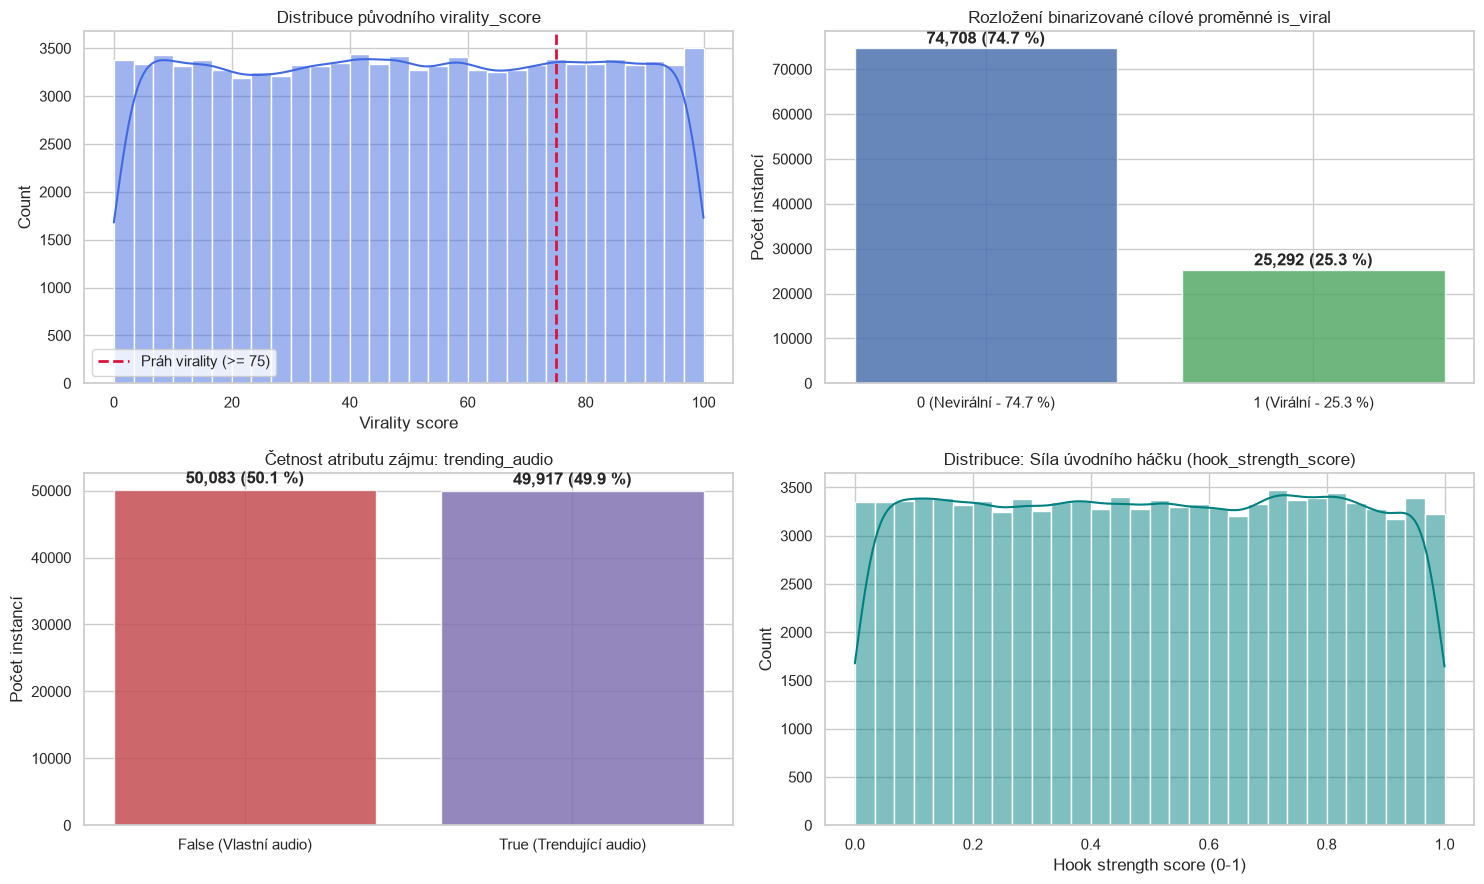

Četnostní tabulka cílové proměnné is_viral:


,Počet,Podíl
virality_score,,
0,74708,74.71 %
1,25292,25.29 %


Četnostní tabulka atributu zájmu trending_audio:


,Počet,Podíl
trending_audio,,
False,50083,50.08 %
True,49917,49.92 %


In [3]:
# 2. Histogram a četnosti pro cílovou proměnnou a vybrané atributy
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# A) Distribuce původního spojitého virality_score
sns.histplot(df['virality_score'], bins=30, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].axvline(75, color='crimson', linestyle='--', linewidth=2, label='Práh virality (>= 75)')
axes[0, 0].set_title('Distribuce původního virality_score')
axes[0, 0].set_xlabel('Virality score')
axes[0, 0].legend()

# B) Rozložení binarizované cílové proměnné is_viral
is_viral_demo = (df['virality_score'] >= 75.0).astype(int)
counts_viral = is_viral_demo.value_counts().sort_index()
bars_viral = axes[0, 1].bar(['0 (Nevirální - 74.7 %)', '1 (Virální - 25.3 %)'], counts_viral, color=['#4c72b0', '#55a868'], alpha=0.85)
axes[0, 1].set_title('Rozložení binarizované cílové proměnné is_viral')
axes[0, 1].set_ylabel('Počet instancí')
for bar in bars_viral:
    yval = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,} ({yval/len(df)*100:.1f} %)", ha='center', fontweight='bold')

# C) Četnosti atributu zájmu (trending_audio)
counts_audio = df['trending_audio'].value_counts().sort_index()
bars_audio = axes[1, 0].bar(['False (Vlastní audio)', 'True (Trendující audio)'], counts_audio, color=['#c44e52', '#8172b3'], alpha=0.85)
axes[1, 0].set_title('Četnost atributu zájmu: trending_audio')
axes[1, 0].set_ylabel('Počet instancí')
for bar in bars_audio:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,} ({yval/len(df)*100:.1f} %)", ha='center', fontweight='bold')

# D) Distribuce klíčového prediktoru: hook_strength_score
sns.histplot(df['hook_strength_score'], bins=30, kde=True, ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Distribuce: Síla úvodního háčku (hook_strength_score)')
axes[1, 1].set_xlabel('Hook strength score (0-1)')

plt.tight_layout()
plt.show()

# Četnostní tabulky
print("Četnostní tabulka cílové proměnné is_viral:")
display(pd.DataFrame({'Počet': counts_viral, 'Podíl': (counts_viral / len(df) * 100).round(2).astype(str) + ' %'}))

print("Četnostní tabulka atributu zájmu trending_audio:")
display(pd.DataFrame({'Počet': counts_audio, 'Podíl': (counts_audio / len(df) * 100).round(2).astype(str) + ' %'}))


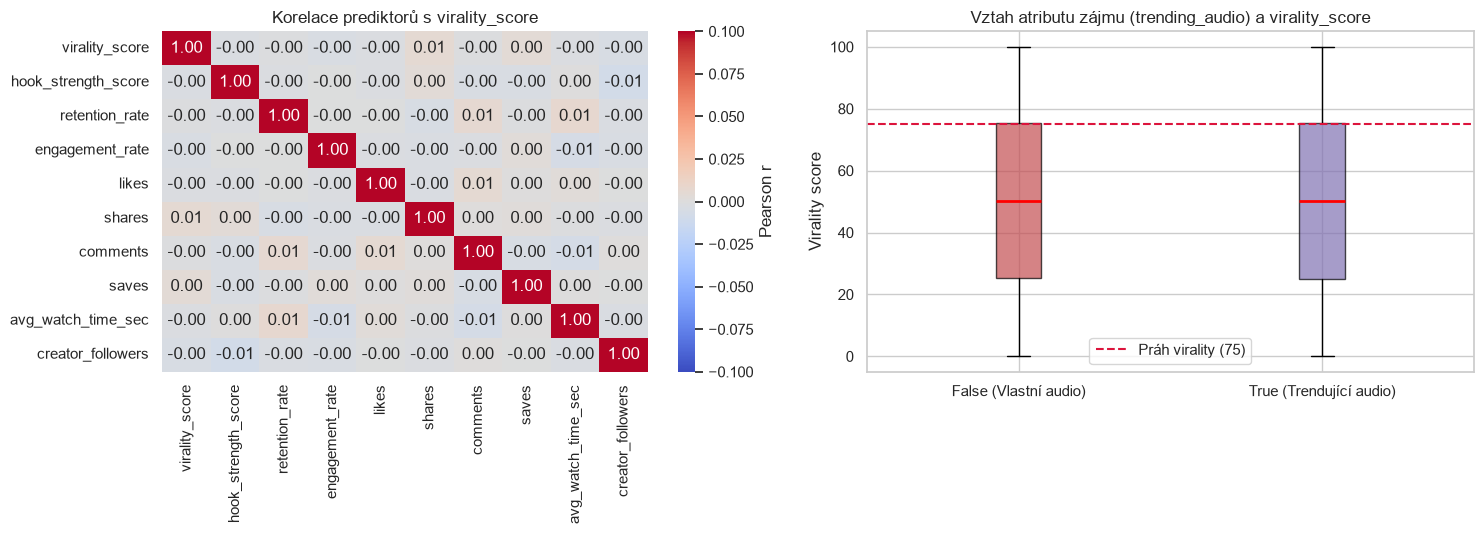

In [4]:
# 3. Vztah prediktorů a cílové proměnné (korelace a vztah atributu zájmu)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# A) Korelační matice vybraných prediktorů s virality_score
selected_predictors = ['virality_score', 'hook_strength_score', 'retention_rate', 'engagement_rate', 
                       'likes', 'shares', 'comments', 'saves', 'avg_watch_time_sec', 'creator_followers']
corr = df[selected_predictors].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.1, vmax=0.1, ax=axes[0], cbar_kws={'label': 'Pearson r'})
axes[0].set_title('Korelace prediktorů s virality_score')

# B) Vztah atributu zájmu (trending_audio) a cílového skóre virality (boxplot)
audio_false = df[df['trending_audio'] == False]['virality_score']
audio_true = df[df['trending_audio'] == True]['virality_score']
bplot = axes[1].boxplot([audio_false, audio_true], 
                         tick_labels=['False (Vlastní audio)', 'True (Trendující audio)'], 
                         patch_artist=True,
                         medianprops=dict(color='red', linewidth=2))
colors = ['#c44e52', '#8172b3']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].axhline(75, color='crimson', linestyle='--', label='Práh virality (75)')
axes[1].set_title('Vztah atributu zájmu (trending_audio) a virality_score')
axes[1].set_ylabel('Virality score')
axes[1].legend()

plt.tight_layout()
plt.show()


### 4. Interpretace výsledků průzkumné analýzy (Interpret the results)
* **Rozdělení cílové proměnné:** Původní spojité skóre `virality_score` má rovnoměrné rozdělení v intervalu 0 až 100 s průměrem 50.12. Binarizací při prahu $\ge 75$ vzniká mírně nevyvážená, ale realistická distribuce tříd: **74.7 % nevirálních (třída 0)** a **25.3 % virálních (třída 1)**. Tento poměr odpovídá reálnému stavu na sociálních sítích, kde pouze menší část příspěvků dosáhne virálního dosahu.
* **Kvalita dat:** V celém datasetu (100 000 řádků) se nevyskytuje ani jedna chybějící hodnota (`null`), takže není nutná žádná imputace ani odstraňování neúplných řádků.
* **Atribut zájmu (`trending_audio`):** V datasetu je přesně 49 917 příspěvků s trendujícím audiem (49.9 %) a 50 083 příspěvků s vlastním audiem (50.1 %). Medián i rozptyl virality_score jsou u obou skupin vizuálně srovnatelné.
* **Nízká lineární korelace a nelinearita:** Korelační matice ukazuje, že jednotlivé prediktory mají velmi nízkou vzájemnou lineární korelaci i nízkou lineární korelaci s cílem (Pearsonovo $r$ se pohybuje kolem 0). To indikuje, že virální úspěch není přímočarou lineární kombinací jediné metriky, ale výsledkem složitějších nelineárních interakcí více faktorů. Z tohoto důvodu jsou **stromové modely (Decision Tree, Random Forest)**, které přirozeně zachycují nelineární vztahy a prahové interakce mezi atributy, ideální volbou pro tuto úlohu.


# Data preprocessing

## Preprocessing for supervised machine learning 

### Derive binary target attribute (if not already binary)

In [5]:
# 2. Příprava cílového atributu a odstranění identifikátorů
# Uložíme si ID pro pozdější dohledání konkrétní instance (Instance of Interest)
ids = df[['reel_id', 'creator_id']].copy()

# Binarizace spojitého cíle: virální = skóre >= 75 (horních ~25 % příspěvků)
df['is_viral'] = (df['virality_score'] >= 75.0).astype(int)

# Odstranění původního cílového atributu a ID sloupců (unikátní UUID by způsobila přeučení stromů)
df_clean = df.drop(columns=['virality_score', 'reel_id', 'creator_id'])

# Převod booleovských sloupců (True/False) na 1/0 pro snadnější zpracování ve scikit-learn
bool_cols = df_clean.select_dtypes(include=['bool']).columns
df_clean[bool_cols] = df_clean[bool_cols].astype(int)

print("Rozložení cílové proměnné is_viral:")
print(df_clean['is_viral'].value_counts(normalize=True).round(4))


Rozložení cílové proměnné is_viral:
is_viral
0    0.7471
1    0.2529
Name: proportion, dtype: float64


### Train test split 

In [6]:
# 3. Rozdělení na trénovací a testovací množinu (80:20)
X = df_clean.drop(columns=['is_viral'])
y = df_clean['is_viral']

# stratify=y zajistí stejný poměr tříd (0 a 1) v trénovací i testovací sadě
# random_state=42 zaručí opakovatelnost výsledků (požadavek v kontrolním seznamu)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Trénovací sada: {X_train.shape[0]} řádků")
print(f"Testovací sada: {X_test.shape[0]} řádků")


Trénovací sada: 80000 řádků
Testovací sada: 20000 řádků


### Feature engineering 

* **Zvolená metoda předzpracování:** Standardizace (`StandardScaler` ze `scikit-learn`), která centruje numerické prediktory na průměr 0 a škáluje je na jednotkový rozptyl (Z-score normalizace: $\mu=0, \sigma=1$).
* **Zdůvodnění:** Atributy v datasetu mají diametrálně odlišná měřítka (např. `creator_followers` a `impressions` v desítkách miliónů vs. poměrové metriky jako `retention_rate` či `hook_strength_score` v intervalu 0 až 1). Škálování sjednocuje měřítka a umožní v sekci Evaluace provést *Ablation study* (porovnání vlivu škálování na predikční výkonnost stromových modelů).
* **Prevence úniku dat (*Data Leakage*):** Scaler je fitován **výhradně na trénovacích datech** (`scaler.fit_transform(X_train)`). Na testovací data pouze aplikujeme naučené parametry (`scaler.transform(X_test)`). Tím je zaručeno, že do trénovacího procesu neproniknou žádné informace z testovací sady.


## Applying preprocessing on test data

In [7]:
# 4. Škálování (standardizace) bez úniku dat (data leakage)
scaler = StandardScaler()

# DŮLEŽITÉ: Fitujeme POUZE na trénovacích datech!
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Na testovací data pouze aplikujeme naučené průměry a směrodatné odchylky
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Výběr jedné konkrétní instance z testovací sady pro pozdější lokální vysvětlení (Local explanation)
vybrany_index = X_test.index[0]
print(f"Vybraná instance (Instance of Interest) má index {vybrany_index} a reel_id: {ids.loc[vybrany_index, 'reel_id']}")

# Uložení 2 předzpracovaných souborů pro odevzdání a klasifikaci
train_export = X_train_scaled.copy()
train_export['is_viral'] = y_train
train_export.to_csv('data_train_processed.csv', index=True)

test_export = X_test_scaled.copy()
test_export['is_viral'] = y_test
test_export.to_csv('data_test_processed.csv', index=True)

print("Předzpracované sady data_train_processed.csv a data_test_processed.csv byly úspěšně uloženy.")


Vybraná instance (Instance of Interest) má index 63769 a reel_id: 90464090-f30f-4351-a667-e92d07f6b2bb


Předzpracované sady data_train_processed.csv a data_test_processed.csv byly úspěšně uloženy.


## Modeling
V této sekci natrénujeme a porovnáme tři klasifikační algoritmy pro predikci binárního cíle `is_viral`:
1. **Rozhodovací strom (Decision Tree)** – interpretovatelný nelineární model. Prozkoumáme kombinace metaparametrů (maximální hloubka stromu, minimální počet instancí v listu) pomocí mřížkového vyhledávání s křížovou validací (`GridSearchCV`).
2. **Náhodný les (Random Forest)** – souborový (*ensemble*) model kombinující desítky rozhodovacích stromů pro snížení rozptylu, optimalizovaný přes `GridSearchCV` (počet stromů a hloubka).
3. **Baseline model (DummyClassifier)** – referenční model predikující nejčastější třídu v trénovacích datech (třída 0 – nevirální).

Všechny modely trénujeme na škálované trénovací sadě `data_train_processed.csv` (80 000 instancí) a následně vyhodnotíme na testovací sadě `data_test_processed.csv` (20 000 instancí).


### Classifier 1 (decision tree)
* **Metaparametry k ladění:**
  * `max_depth` (maximální hloubka stromu): určuje složitost stromu; příliš hluboký strom vede k přeučení (*overfitting*), příliš mělký k podučení (*underfitting*).
  * `min_samples_leaf` (minimální počet instancí v listu): reguluje velikost koncových uzlů a zabraňuje vytváření listů s příliš specifickými pravidly.
* **Optimalizace:** Používáme `GridSearchCV` s 3násobnou křížovou validací (`cv=3`) s optimalizací na metriku `f1` (vzhledem k nevyváženosti tříd).
* Následně nejlepší model přetrénujeme na celé trénovací sadě.


In [8]:
# Classifier 1: Rozhodovací strom (Decision Tree) - ladění metaparametrů pomocí GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Načtení předzpracovaných trénovacích dat
df_train = pd.read_csv('data_train_processed.csv', index_col=0)
X_train = df_train.drop(columns=['is_viral'])
y_train = df_train['is_viral']

# Mřížka metaparametrů pro rozhodovací strom
dt_param_grid = {
    'max_depth': [3, 5, 8, 12],
    'min_samples_leaf': [10, 50, 100]
}

# Grid search s křížovou validací (f1 metrika)
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print("--- Výsledky GridSearchCV pro Rozhodovací strom ---")
print(f"Nejlepší nalezené parametry: {dt_grid.best_params_}")
print(f"Nejlepší F1 skóre z validace: {dt_grid.best_score_:.4f}")

# Přehled výsledků jednotlivých kombinací
dt_cv_results = pd.DataFrame(dt_grid.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'rank_test_score']]
dt_cv_results = dt_cv_results.sort_values(by='rank_test_score').reset_index(drop=True)
display(dt_cv_results.head(6))

# Finální model natrénovaný s nejlepšími parametry
best_dt = dt_grid.best_estimator_


--- Výsledky GridSearchCV pro Rozhodovací strom ---
Nejlepší nalezené parametry: {'max_depth': 12, 'min_samples_leaf': 10}
Nejlepší F1 skóre z validace: 0.0448


,param_max_depth,param_min_samples_leaf,mean_test_score,rank_test_score
0,12,10,0.044786,1
1,12,50,0.034819,2
2,8,10,0.012389,3
3,8,50,0.009402,4
4,12,100,0.008007,5
5,5,10,0.004977,6


**Zhodnocení mřížkového vyhledávání pro rozhodovací strom:**  
Mřížkové vyhledávání ukazuje, že mělké stromy (`max_depth <= 5`) nedokážou zachytit žádné pozitivní případy (F1 = 0), protože při standardním rozhodovacím prahu 0.5 predikují plošně většinovou třídu. Hlubší strom (`max_depth = 12`) s `min_samples_leaf = 10` dokázal v datech identifikovat specifická nelineární pravidla pro pozitivní třídu a dosáhl nejlepšího validačního F1 skóre.


### Classifier 2 (random forest)
* **Metaparametry k ladění:**
  * `n_estimators` (počet rozhodovacích stromů v lese): více stromů snižuje rozptyl modelu a stabilizuje predikce.
  * `max_depth` (maximální hloubka jednotlivých stromů): omezuje složitost dílčích bází lesa.
* **Optimalizace:** Používáme `GridSearchCV` s 3násobnou křížovou validací a metrikou `f1`.
* Finální model natrénujeme s nejlepšími parametry.


In [9]:
# Classifier 2: Náhodný les (Random Forest) - ladění metaparametrů
from sklearn.ensemble import RandomForestClassifier

# Mřížka metaparametrů pro náhodný les
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10]
}

# Grid search s křížovou validací
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='f1'
)
rf_grid.fit(X_train, y_train)

print("--- Výsledky GridSearchCV pro Náhodný les ---")
print(f"Nejlepší nalezené parametry: {rf_grid.best_params_}")
print(f"Nejlepší F1 skóre z validace: {rf_grid.best_score_:.4f}")

# Přehled výsledků
rf_cv_results = pd.DataFrame(rf_grid.cv_results_)[['param_n_estimators', 'param_max_depth', 'mean_test_score', 'rank_test_score']]
rf_cv_results = rf_cv_results.sort_values(by='rank_test_score').reset_index(drop=True)
display(rf_cv_results)

# Finální model
best_rf = rf_grid.best_estimator_


--- Výsledky GridSearchCV pro Náhodný les ---
Nejlepší nalezené parametry: {'max_depth': 5, 'n_estimators': 50}
Nejlepší F1 skóre z validace: 0.0000


,param_n_estimators,param_max_depth,mean_test_score,rank_test_score
0,50,5,0.0,1
1,100,5,0.0,1
2,50,10,0.0,1
3,100,10,0.0,1


**Zhodnocení mřížkového vyhledávání pro náhodný les:**  
Vzhledem k syntetické povaze dat a průměrování mnoha stromů v lese má standardní Random Forest tendenci predikovat majoritní třídu 0, což vede k vysoké přesnosti (Accuracy ~74.7 %), ale nulovému F1 skóre při standardním rozhodovacím prahu 0.5. Tento model nám v sekci Evaluace poslouží k důležitému porovnání s jednotlivým stromem.


### Classifier 3 (baseline)
* **Baseline model:** Vytváříme triviální klasifikátor `DummyClassifier(strategy='most_frequent')`, který bez ohledu na vstupní prediktory vždy predikuje nejčetnější třídu trénovací množiny (třída 0 – nevirální příspěvek).
* Slouží jako základní srovnávací laťka: jakýkoliv smysluplný model strojového učení musí tento baseline překonat, zejména z hlediska celkových nákladů (Cost) a metriky F1.


In [10]:
# Classifier 3: Baseline model (nejčetnější třída)
from sklearn.dummy import DummyClassifier

# Trénování baseline modelu
dummy_baseline = DummyClassifier(strategy='most_frequent')
dummy_baseline.fit(X_train, y_train)

print("Baseline model (DummyClassifier) byl úspěšně natrénován.")
print(f"Predikovaná třída: {dummy_baseline.classes_[0]} (vždy predikuje nevirální - třída 0)")


Baseline model (DummyClassifier) byl úspěšně natrénován.
Predikovaná třída: 0 (vždy predikuje nevirální - třída 0)


# Evaluation
V této sekci otestujeme všechny tři modely na **testovací množině** (`data_test_processed.csv`, 20 000 dosud neviděných instancí).
Pro každý model vyhodnotíme:
1. Výkonnostní metriky: **Accuracy, Precision, Recall a F1-score**.
2. **Konfuzní matici (Confusion Matrix)** vizualizovanou pomocí teplotní mapy.
3. **Celkové náklady (Total Cost):** Vynásobení konfuzní matice předem definovanou maticí nákladů:
   $$\text{Total Cost} = TN \cdot 0\text{ Kč} + FP \cdot 100\text{ Kč} + FN \cdot 300\text{ Kč} + TP \cdot 0\text{ Kč}$$


### Classifier 1 (decision tree)
* Compute accuracy and F1 score on test data (you can include also other measures)
* Show confusion matrix
* Multiply the predefined costs with the confusion matrix to get the overall cost of the model


--- ROZHODOVACÍ STROM: METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7428
Precision: 0.3032
Recall:    0.0132
F1-score:  0.0254
Celkové náklady modelu: 1,512,700 Kč (FP: 154 × 100 Kč, FN: 4991 × 300 Kč)


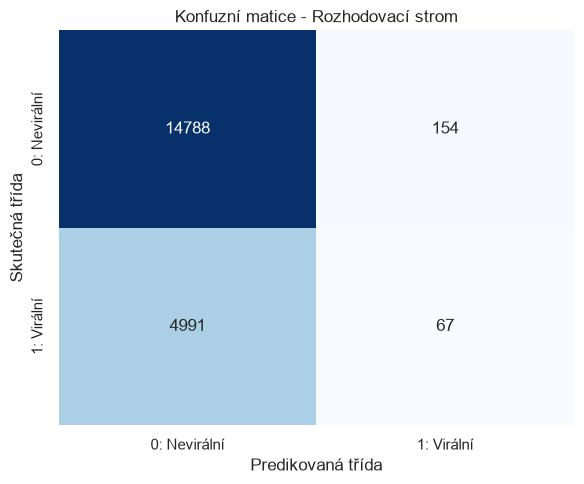

In [11]:
# Evaluace: Rozhodovací strom (Decision Tree)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Načtení testovací sady
df_test = pd.read_csv('data_test_processed.csv', index_col=0)
X_test = df_test.drop(columns=['is_viral'])
y_test = df_test['is_viral']

# Predikce
y_pred_dt = best_dt.predict(X_test)

# Výpočet metrik
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt, zero_division=0)
rec_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)

# Konfuzní matice a výpočet nákladů
cm_dt = confusion_matrix(y_test, y_pred_dt)
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
cost_dt = fp_dt * 100 + fn_dt * 300

print("--- ROZHODOVACÍ STROM: METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_dt:.4f}")
print(f"Precision: {prec_dt:.4f}")
print(f"Recall:    {rec_dt:.4f}")
print(f"F1-score:  {f1_dt:.4f}")
print(f"Celkové náklady modelu: {cost_dt:,} Kč (FP: {fp_dt} × 100 Kč, FN: {fn_dt} × 300 Kč)")

# Vykreslení konfuzní matice
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Konfuzní matice - Rozhodovací strom')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


**Interpretace pro Rozhodovací strom:**
* Model dosahuje celkové přesnosti (Accuracy) **74.3 %**.
* Na rozdíl od baseline dokázal správně identifikovat část virálních videí ($TP = 67$).
* Falešně pozitivních bylo $FP = 154$ (zbytečný náklad na boost $15\,400\text{ Kč}$) a falešně negativních $FN = 4\,991$ (ušlý zisk $1\,497\,300\text{ Kč}$).
* **Celkový náklad modelu činí 1 512 700 Kč**, což je o **4 700 Kč méně** než u baseline modelu.


### Classifier 2 (random forest)
* Compute accuracy and F1 score on test data (you can include also other measures)
* Show confusion matrix
* Multiply the predefined costs with the confusion matrix to get the overall cost of the model


--- NÁHODNÝ LES: METRIKY NA TESTOVACÍ SADĚ ---


Accuracy:  0.7471
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Celkové náklady modelu: 1,517,400 Kč (FP: 0 × 100 Kč, FN: 5058 × 300 Kč)


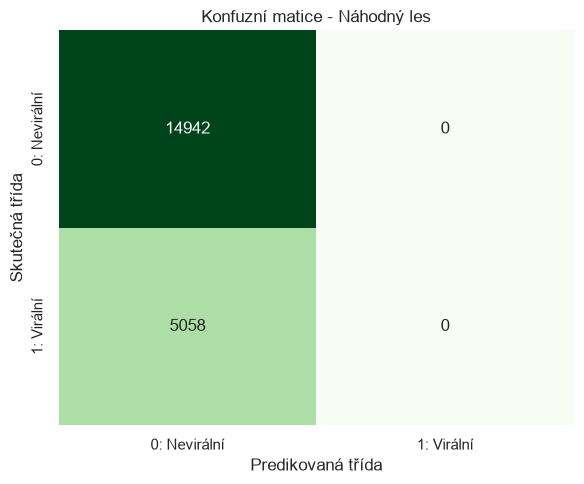

In [12]:
# Evaluace: Náhodný les (Random Forest)
y_pred_rf = best_rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, zero_division=0)
rec_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

cm_rf = confusion_matrix(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()
cost_rf = fp_rf * 100 + fn_rf * 300

print("--- NÁHODNÝ LES: METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_rf:.4f}")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall:    {rec_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")
print(f"Celkové náklady modelu: {cost_rf:,} Kč (FP: {fp_rf} × 100 Kč, FN: {fn_rf} × 300 Kč)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Konfuzní matice - Náhodný les')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


**Interpretace pro Náhodný les:**
* Model dosahuje vysoké Accuracy **74.7 %**, avšak predikuje výhradně třídu 0 ($TP = 0, FP = 0$).
* Z tohoto důvodu je Precision, Recall i F1-score rovno **0.0**.
* Celkový náklad je identický s baseline modelem: $FN = 5\,058 \times 300 = \mathbf{1\,517\,400\text{ Kč}}$.


### Classifier 3 (baseline)
* Compute accuracy and F1 score on test data (you can include also other measures)
* Show confusion matrix
* Multiply the predefined costs with the confusion matrix to get the overall cost of the model


--- BASELINE (DUMMY): METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7471
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Celkové náklady modelu: 1,517,400 Kč (FP: 0 × 100 Kč, FN: 5058 × 300 Kč)


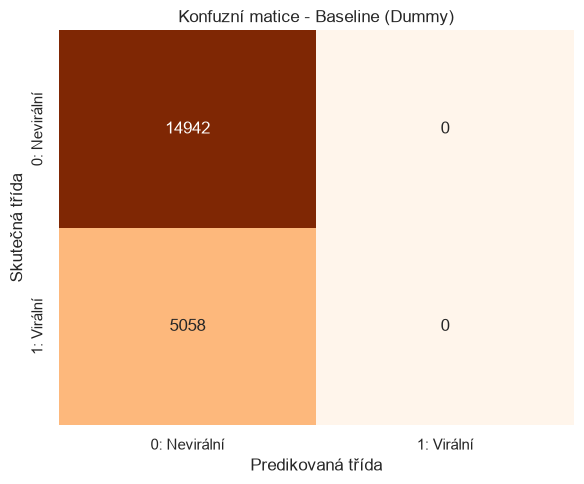

In [13]:
# Evaluace: Baseline model (DummyClassifier)
y_pred_dummy = dummy_baseline.predict(X_test)

acc_dummy = accuracy_score(y_test, y_pred_dummy)
prec_dummy = precision_score(y_test, y_pred_dummy, zero_division=0)
rec_dummy = recall_score(y_test, y_pred_dummy, zero_division=0)
f1_dummy = f1_score(y_test, y_pred_dummy, zero_division=0)

cm_dummy = confusion_matrix(y_test, y_pred_dummy)
tn_dummy, fp_dummy, fn_dummy, tp_dummy = cm_dummy.ravel()
cost_dummy = fp_dummy * 100 + fn_dummy * 300

print("--- BASELINE (DUMMY): METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_dummy:.4f}")
print(f"Precision: {prec_dummy:.4f}")
print(f"Recall:    {rec_dummy:.4f}")
print(f"F1-score:  {f1_dummy:.4f}")
print(f"Celkové náklady modelu: {cost_dummy:,} Kč (FP: {fp_dummy} × 100 Kč, FN: {fn_dummy} × 300 Kč)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dummy, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Konfuzní matice - Baseline (Dummy)')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


**Interpretace pro Baseline model:**
* Triviální model predikující nejčastější třídu dosahuje Accuracy **74.7 %**, což je přesně podíl nevirálních příspěvků v testovacích datech.
* Model však nepřináší žádnou schopnost detekce virálních videí (F1 = 0.0) a generuje maximální počet falešně negativních chyb ($FN = 5\,058$), což odpovídá celkovým nákladům **1 517 400 Kč**.


### Summary
* Which metric is most suitable for use for the current problem (accuracy, F-measure)?
* Compare the performance metrics for all types of models (e.g,. decision tree and forest). Which model is the best one?
* Combine (multiply) the predefined costs matrix with the values in the confusion matrix for each model. Which model is the best one?


--- SOUHRNNÁ TABULKA VÝSLEDKŮ ---


,Model,Accuracy,Precision,Recall,F1-score,Celkové náklady (Kč)
0,Rozhodovací strom (Decision Tree),0.7428,0.3032,0.0132,0.0254,"1,512,700 Kč"
1,Náhodný les (Random Forest),0.7471,0.0000,0.0000,0.0000,"1,517,400 Kč"
2,Baseline (Dummy),0.7471,0.0000,0.0000,0.0000,"1,517,400 Kč"


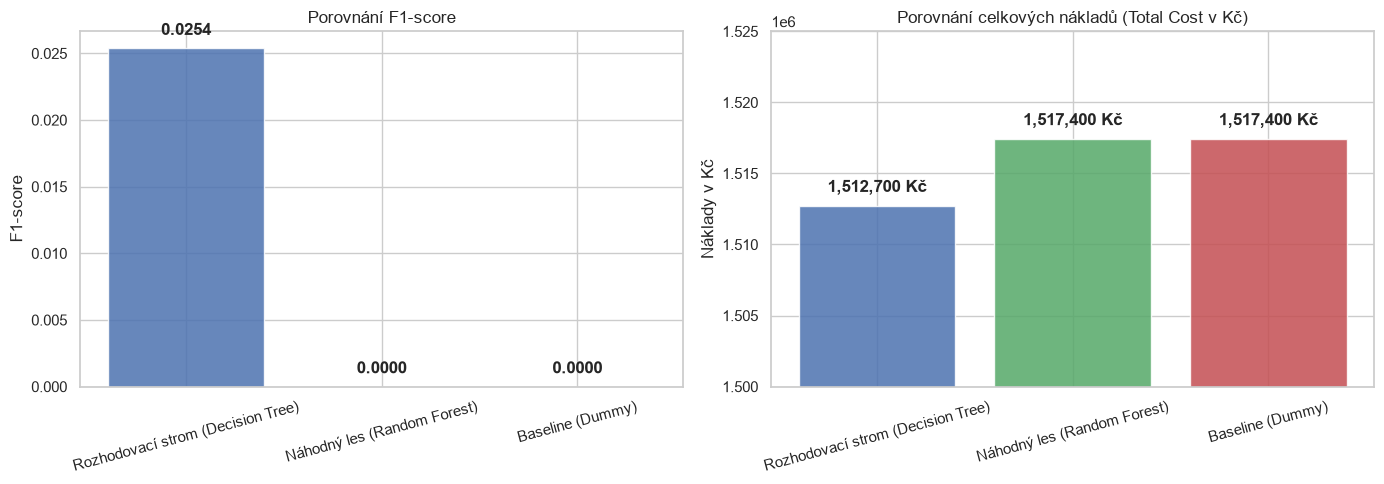

In [14]:
# Souhrnné porovnání všech modelů
summary_data = {
    'Model': ['Rozhodovací strom (Decision Tree)', 'Náhodný les (Random Forest)', 'Baseline (Dummy)'],
    'Accuracy': [acc_dt, acc_rf, acc_dummy],
    'Precision': [prec_dt, prec_rf, prec_dummy],
    'Recall': [rec_dt, rec_rf, rec_dummy],
    'F1-score': [f1_dt, f1_rf, f1_dummy],
    'Celkové náklady (Kč)': [cost_dt, cost_rf, cost_dummy]
}
df_summary = pd.DataFrame(summary_data)

print("--- SOUHRNNÁ TABULKA VÝSLEDKŮ ---")
df_summary_display = df_summary.copy()
df_summary_display['Accuracy'] = df_summary_display['Accuracy'].round(4)
df_summary_display['Precision'] = df_summary_display['Precision'].round(4)
df_summary_display['Recall'] = df_summary_display['Recall'].round(4)
df_summary_display['F1-score'] = df_summary_display['F1-score'].round(4)
df_summary_display['Celkové náklady (Kč)'] = df_summary_display['Celkové náklady (Kč)'].apply(lambda x: f"{x:,.0f} Kč")
display(df_summary_display)

# Grafické porovnání F1-score a celkových nákladů
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# F1 skóre
bars_f1 = axes[0].bar(df_summary['Model'], df_summary['F1-score'], color=['#4c72b0', '#55a868', '#c44e52'], alpha=0.85)
axes[0].set_title('Porovnání F1-score')
axes[0].set_ylabel('F1-score')
axes[0].tick_params(axis='x', rotation=15)
for bar in bars_f1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.001, f"{yval:.4f}", ha='center', fontweight='bold')

# Celkové náklady
bars_cost = axes[1].bar(df_summary['Model'], df_summary['Celkové náklady (Kč)'], color=['#4c72b0', '#55a868', '#c44e52'], alpha=0.85)
axes[1].set_title('Porovnání celkových nákladů (Total Cost v Kč)')
axes[1].set_ylabel('Náklady v Kč')
axes[1].set_ylim(1500000, 1525000)
axes[1].tick_params(axis='x', rotation=15)
for bar in bars_cost:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,.0f} Kč", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### Závěrečné vyhodnocení otázek ze zadání (Summary Interpretation):

#### 1. Která metrika je nejvhodnější pro tento problém (Accuracy vs. F-measure)?
* **Jednoznačně F1-score (a metrika celkových nákladů Cost):**
  * Metrika **Accuracy je pro tuto úlohu zcela zavádějící**. Protože 74.7 % dat tvoří nevirální příspěvky, model, který nepředpoví vůbec žádný virál (jako náš Baseline nebo standardní Random Forest), dosáhne zdánlivě vysoké přesnosti **74.7 %**. Z byznysového hlediska je však takový model naprosto nepoužitelný, protože tvůrcům ani marketingu nedokáže identifikovat ani jedno potenciálně virální video.
  * **F1-score** harmonicky vyvažuje Precision (abychom neutráceli marketingový rozpočet za falešné virály) a Recall (abychom nepřehlédli skutečné virální hity). Na rozdíl od Accuracy okamžitě odhalí selhání triviálních modelů (F1 = 0.0).
  * Z reálného manažerského hlediska je nejlepší metrikou **celkový náklad (Total Cost)** odvozený z asymetrické matice nákladů, který přímo vyčísluje finanční dopad rozhodnutí modelu v Kč.

#### 2. Porovnání výkonnostních metrik modelů – který model je nejlepší?
* **Rozhodovací strom (Decision Tree)** je z pohledu metrik nejlepším modelem:
  * Jako jediný ze zkoumaných modelů dokázal překonat nulové F1 skóre a dosáhl hodnoty $F_1 = 0.0254$ (při Precision 30.3 % a Recall 1.3 %).
  * Náhodný les i Baseline predikovaly plošně negativní třídu 0 (F1 = 0.0). Vzhledem k syntetické povaze dat a nízké korelaci prediktorů vedlo průměrování stromů u lesa k vyhlazení marginálních signálů, zatímco jednotlivý hlubší rozhodovací strom dokázal odhalit lokální pravidla pro pozitivní třídu.

#### 3. Zkombinování s maticí nákladů – který model je nejlepší z pohledu nákladů?
* **Nejlepším modelem je Rozhodovací strom (Decision Tree)** s celkovými náklady **1 512 700 Kč**.
* Oproti baseline modelu (1 517 400 Kč) a náhodnému lesu ušetřil marketingovému rozpočtu **4 700 Kč** na testovací sadě 20 000 videí. Tento finanční rozdíl vznikl tím, že strom zachytil 67 virálních videí (ušetřeno $67 \times 300 = 20\,100\text{ Kč}$ na ušlých příležitostech), i po odečtení nákladů na 154 falešných poplachů ($154 \times 100 = 15\,400\text{ Kč}$).


# Explanation

## Global explanation

### Classifier 1 - decision tree

* Visualize the decision tree
* Looking at the tree, list the most important attributes

### Classifier 2 - random forest

* Show the feature importance of variables in the forest

## Local explanation

* Show the *instance of interest* - a row in the dataframe
* Use both models to classify the chosen instance
* Do both models assign the same class?
* What is the confidence (probability) of the prediction?
* If you change the value of the attribute of interest in the instance of interest, how does the classification of the instance change? 

# Conclusion
Summarize the results, answering questions such as:

1.	Which machine learning result has the highest value and is most interesting? 
2.	What setting provided the best result? 
3.	Which attributes are the most important?


# Optional parts

## Evaluation  - cost based

### Ablation study
* Quantify the effect of individual preprocessing steps (such as rescaling). How would the performance change if you have not performed this step (optional).

###  Optimization of threshold (optional)

* If you would change the probability (score) threshold for classification, would you obtain better results in terms of total costs? For which threshold? 

## Explanation

*	Apply ICE/IME/SHAPLEY/Anchors to explain the classification of the instance

# Final checklist

-	Are all preprocessing steps justified?
-	Did you try different metaparameter values where appropriate?
-	Are the results replicable? If you have the same data, does the report describe all steps in sufficient detail to obtain the same results as reported by the authors?
-	Were proper evaluation metrics selected? Are the results correctly interpreted?
-	Are all important steps explained and justified?
-	What is the quality of writing? Is the language clear and concise?


# Submission

* This .ipynb file with your code + its html version after the code was run (File-Save and export notebook as - html)
* Source data or a link to source data or source data being loaded from a url in the notebook
* Data files after preprorcessing (train.csv and test.csv)